In [1]:
import torch 
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset,DataLoader


### Data proccessing function

In [2]:
def get_data(data_name):
    with open(data_name,'r') as data:
        return data.read()


In [3]:
# 1. Dictionnaires de Mapping
# Acides aminés standards
AA_MAP = {
    'A': 0, 'C': 1, 'D': 2, 'E': 3, 'F': 4, 'G': 5, 'H': 6, 'I': 7, 'K': 8, 'L': 9, 
    'M': 10, 'N': 11, 'P': 12, 'Q': 13, 'R': 14, 'S': 15, 'T': 16, 'V': 17, 'W': 18, 'Y': 19,
    '<PAD>': 20  # Le Spacer pour les bords
}

# Labels: h=Helix, e=Sheet, _=Coil
LABEL_MAP = {'h': 0, 'e': 1, '_': 2}

In [4]:


def parse_raw_data(raw_text):
    """
    Lit le texte brut et retourne une liste de protéines.
    Chaque protéine est un tuple (liste_indices_aa, liste_indices_labels)
    """
    proteins = []
    current_aa_seq = []
    current_label_seq = []
    
    lines = raw_text.strip().split('\n')
    
    for line in lines:
        line = line.strip()
        if not line: continue
        
        if line == '<>':
            # Nouvelle protéine : sauvegarde la précédente si elle existe, puis réinitialise
            if current_aa_seq:
                proteins.append((current_aa_seq, current_label_seq))
            current_aa_seq = []
            current_label_seq = []
        else:
            # Ligne de donnée : "E _" ou "F h"
            parts = line.split()
            if len(parts) == 2:
                aa, label = parts[0], parts[1]
                # Conversion immédiate en entiers
                if aa in AA_MAP:
                    current_aa_seq.append(AA_MAP[aa])
                    current_label_seq.append(LABEL_MAP[label])
    
    # Sauvegarde la dernière protéine si elle existe
    if current_aa_seq:
        proteins.append((current_aa_seq, current_label_seq))
    
    return proteins



In [5]:
def create_windows(proteins, window_size=13):
    """
    Transforme les séquences complètes en fenêtres glissantes.
    Retourne X (inputs) et Y (targets).
    """
    half_window = window_size // 2
    X = []
    Y = []
    
    for aa_seq, label_seq in proteins:
        # Longueur de la protéine
        L = len(aa_seq)
        
        # On ajoute du Padding (Spacer) au début et à la fin de la séquence
        # pour pouvoir centrer la fenêtre sur le premier et le dernier élément
        padded_seq = [AA_MAP['<PAD>']] * half_window + aa_seq + [AA_MAP['<PAD>']] * half_window
        
        # Glissement de la fenêtre
        for i in range(L):
            # i correspond à la position du résidu central dans la séquence originale
            # Dans padded_seq, le résidu central est à l'index i + half_window
            window = padded_seq[i : i + window_size]
            target = label_seq[i]
            
            X.append(window)
            Y.append(target)
            
    return torch.tensor(X, dtype=torch.long), torch.tensor(Y, dtype=torch.long)



In [6]:

# X_batch contient des entiers [Batch_Size, 13]
# On convertit en One-Hot float : [Batch_Size, 13, 21]
def one_hot(data):
    X_one_hot = F.one_hot(data, num_classes=21).float() 

    # Le modèle attend (Batch, 273), donc on aplatit
    print(X_one_hot.shape)
    X_one_hot=X_one_hot.reshape(X_one_hot.shape[0],X_one_hot.shape[1]*X_one_hot.shape[2])
    print(X_one_hot.shape)
    return X_one_hot




In [7]:
"""
#Fonction pour écrire les protéines dans un fichier

def write_proteins_to_file(proteins, filename):
    with open(filename, 'w') as f:
        for aa_seq, label_seq in proteins:
            f.write('<>\n')
            for aa_idx, label_idx in zip(aa_seq, label_seq):
                aa = [k for k, v in AA_MAP.items() if v == aa_idx and k != '<PAD>'][0]
                label = [k for k, v in LABEL_MAP.items() if v == label_idx][0]
                f.write(f'{aa} {label}\n')
            f.write('<end>\n')

# Créer le fichier de validation
raw_data_sample = get_data('protein-secondary-structure-real.train')

data = parse_raw_data(raw_data_sample)
print(f"Nombre de protéines trouvées : {len(data)}")

# Split des protéines en train et validation
train_proteins, val_proteins = train_test_split(data, test_size=0.1, random_state=42)


write_proteins_to_file(val_proteins, 'protein-secondary-structure.val')
write_proteins_to_file(train_proteins, 'protein-secondary-structure.train')

print("Fichier 'protein-secondary-structure.val' créé avec les protéines de validation.")

"""

'\n#Fonction pour écrire les protéines dans un fichier\n\ndef write_proteins_to_file(proteins, filename):\n    with open(filename, \'w\') as f:\n        for aa_seq, label_seq in proteins:\n            f.write(\'<>\n\')\n            for aa_idx, label_idx in zip(aa_seq, label_seq):\n                aa = [k for k, v in AA_MAP.items() if v == aa_idx and k != \'<PAD>\'][0]\n                label = [k for k, v in LABEL_MAP.items() if v == label_idx][0]\n                f.write(f\'{aa} {label}\n\')\n            f.write(\'<end>\n\')\n\n# Créer le fichier de validation\nraw_data_sample = get_data(\'protein-secondary-structure-real.train\')\n\ndata = parse_raw_data(raw_data_sample)\nprint(f"Nombre de protéines trouvées : {len(data)}")\n\n# Split des protéines en train et validation\ntrain_proteins, val_proteins = train_test_split(data, test_size=0.1, random_state=42)\n\n\nwrite_proteins_to_file(val_proteins, \'protein-secondary-structure.val\')\nwrite_proteins_to_file(train_proteins, \'protein-s

In [8]:
def plot_history(train_losses, val_losses):
    plt.figure(figsize=(10, 5))
    
    # 1. Tracer les courbes
    # On ajuste l'axe X pour qu'il corresponde aux époques
    epochs_range = range(0, len(val_losses) * 10, 10) 
    
    plt.plot(train_losses, label='Training Loss', color='blue', alpha=0.6)
    plt.plot(epochs_range, val_losses, label='Validation Loss', color='orange', linewidth=2)
    
    # 2. TROUVER ET AFFICHER LE MINIMUM
    min_val_loss = min(val_losses)
    min_idx = val_losses.index(min_val_loss)
    best_epoch = min_idx * 10
    
    # On ajoute un point rouge sur le minimum
    plt.scatter(best_epoch, min_val_loss, color='red', s=100, zorder=5, label='Best Model')
    
    # On écrit le texte à côté
    plt.annotate(f'Min: {min_val_loss:.4f}\n(Epoch {best_epoch})',
                 xy=(best_epoch, min_val_loss), 
                 xytext=(best_epoch + 20, min_val_loss + 0.1),
                 arrowprops=dict(facecolor='black', shrink=0.05))

    plt.title("Évolution de la Loss (Erreur)")
    plt.xlabel("Époques")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()



In [9]:
# --- UTILISATION ---

raw_data_sample = get_data('protein-secondary-structure.train')

data_train = parse_raw_data(raw_data_sample)
print(f"Nombre de protéines trouvées : {len(data_train)}")


X_true, y_true = create_windows(data_train, window_size=13)


print(f"\nExemple de fenêtre (Input X): {X_true[0]}")
print(f"Indices: {X_true[0].tolist()}")
print(f"Label (Target y): {y_true[0]} (0=h, 1=e, 2=_)")
print(f"Forme totale des données X train: {X_true.shape}")


Nombre de protéines trouvées : 99

Exemple de fenêtre (Input X): tensor([20, 20, 20, 20, 20, 20,  5, 17,  5, 16, 17, 12, 10])
Indices: [20, 20, 20, 20, 20, 20, 5, 17, 5, 16, 17, 12, 10]
Label (Target y): 2 (0=h, 1=e, 2=_)
Forme totale des données X train: torch.Size([16072, 13])


In [10]:
# --- UTILISATION ---

raw_data_sample = get_data('protein-secondary-structure.val')

val_train = parse_raw_data(raw_data_sample)

X_val, y_val = create_windows(val_train, window_size=13)

print(f"Nombre de protéines val : {len(val_train)}")

print(f"\nExemple de fenêtre (Input X): {X_val[0]}")
print(f"Indices: {X_val[0].tolist()}")
print(f"Label (Target y): {y_val[0]} (0=h, 1=e, 2=_)")
print(f"Forme totale des données X train: {X_val.shape}")

#

Nombre de protéines val : 12

Exemple de fenêtre (Input X): tensor([20, 20, 20, 20, 20, 20,  0, 16,  8,  0, 17,  1, 17])
Indices: [20, 20, 20, 20, 20, 20, 0, 16, 8, 0, 17, 1, 17]
Label (Target y): 2 (0=h, 1=e, 2=_)
Forme totale des données X train: torch.Size([2033, 13])


In [11]:
# --- UTILISATION ---

raw_data_sample = get_data('protein-secondary-structure.test')

data = parse_raw_data(raw_data_sample)
print(f"Nombre de protéines test : {len(data)}")

x_test, y_test = create_windows(data, window_size=13)

print(f"\nExemple de fenêtre (Input X): {x_test[0]}")
print(f"Indices: {x_test[0].tolist()}")
print(f"Label (Target y): {y_test[0]} (0=h, 1=e, 2=_)")
print(f"Forme totale des données X: {x_test.shape}")

Nombre de protéines test : 17

Exemple de fenêtre (Input X): tensor([20, 20, 20, 20, 20, 20,  3, 11,  9,  8,  9,  5,  4])
Indices: [20, 20, 20, 20, 20, 20, 3, 11, 9, 8, 9, 5, 4]
Label (Target y): 2 (0=h, 1=e, 2=_)
Forme totale des données X: torch.Size([3520, 13])


In [12]:
x_one_hot_train=one_hot(X_true)
x_one_hot_val=one_hot(X_val)
x_one_hot_test=one_hot(x_test)

torch.Size([16072, 13, 21])
torch.Size([16072, 273])
torch.Size([2033, 13, 21])
torch.Size([2033, 273])
torch.Size([3520, 13, 21])
torch.Size([3520, 273])


In [13]:
#cpu or gpu
device='cuda' if torch.cuda.is_available() else 'cpu'
x_one_hot_train=x_one_hot_train.to(device)
x_one_hot_val=x_one_hot_val.to(device)
x_one_hot_test=x_one_hot_test.to(device)

x_test=x_test.to(device)
X_true=X_true.to(device)
X_val=X_val.to(device)

y_test=y_test.to(device)
y_true=y_true.to(device)
y_val=y_val.to(device)

In [14]:
#batch_size
batch_size = 32 


train_dataset = TensorDataset(x_one_hot_train, y_true)
val_dataset   = TensorDataset(x_one_hot_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f"{len(train_loader)} batchs par époque.")

503 batchs par époque.


In [15]:
"""
class MLP(nn.Module):
    
    def __init__(self,window_size=13,vocab_size=21):
        
        super().__init__()
        
        input_size=window_size*vocab_size

        self.model=nn.Sequential(
            nn.Linear(input_size,128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128,40),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(40,3)

        )
    def forward(self,x):
        return self.model(x)

"""

'\nclass MLP(nn.Module):\n    \n    def __init__(self,window_size=13,vocab_size=21):\n        \n        super().__init__()\n        \n        input_size=window_size*vocab_size\n\n        self.model=nn.Sequential(\n            nn.Linear(input_size,128),\n            nn.ReLU(),\n            nn.Dropout(0.2),\n            nn.Linear(128,40),\n            nn.ReLU(),\n            nn.Dropout(0.3),\n            nn.Linear(40,3)\n\n        )\n    def forward(self,x):\n        return self.model(x)\n\n'

In [16]:
class MLP(nn.Module):
    
    def __init__(self,window_size=13,vocab_size=21):
        
        super().__init__()
        
        input_size=window_size*vocab_size

        self.model=nn.Sequential(
            nn.Linear(input_size,128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128,40),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(40,3)

        )
    def forward(self,x):
        return self.model(x)

In [17]:
#torch.manual_seed(42)


In [ ]:
import torch
import torch.nn as nn
import numpy as np
import random
import copy
import time

# --- CONFIGURATION DE LA BATAILLE ---
# Nombre total d'essais (Tu peux mettre 100 si tu as le temps)
NUM_TRIALS = 50 

# Patience pour tuer les modèles nuls rapidement
PATIENCE = 15 
MAX_EPOCHS = 100 # Pas besoin de 900, l'early stopping coupera avant

# Variables pour stocker le GRAND VAINQUEUR
global_best_acc = 0.0
global_best_model_state = None
global_best_params = {}

print(f"🥊 DÉBUT DE LA BATTLE ROYALE : {NUM_TRIALS} COMBATTANTS")
print("="*60)

start_time = time.time()

for trial in range(1, NUM_TRIALS + 1):
    
    # 1. TIRAGE AU SORT DES ARMES (Hyperparamètres)
    # Graine aléatoire entre 0 et 10000
    seed = random.randint(0, 10000)
    
    # Learning Rate aléatoire sur échelle Logarithmique (entre 0.0001 et 0.01)
    # C'est mieux que l'aléatoire normal car ça explore les petits et les gros ordres de grandeur
    lr_log = np.random.uniform(-4, -2) # -4 = 10^-4, -2 = 10^-2
    lr = 10 ** lr_log
    
    # 2. APPLICATION DE LA GRAINE (Reproductibilité pour ce trial)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        
    # 3. CRÉATION DU COMBATTANT
    # Important : On recrée le modèle de zéro à chaque fois !
    model = MLP().to(device) 
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    
    # Variables locales pour ce round
    best_val_acc_round = 0.0
    patience_counter = 0
    epoch_stop = 0
    
    # --- COMBAT (Entraînement) ---
    for epoch in range(MAX_EPOCHS):
        model.train()
        
        # Train Loop
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            
            optimizer.zero_grad()
            logits = model(x_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            
        # --- VALIDATION (Juge de paix) ---
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for x_val, y_val in val_loader:
                x_val, y_val = x_val.to(device), y_val.to(device)
                logits_val = model(x_val)
                preds = torch.argmax(logits_val, dim=1)
                correct += (preds == y_val).sum().item()
                total += y_val.size(0)
        
        val_acc = correct / total
        
        # --- EARLY STOPPING LOGIC ---
        if val_acc > best_val_acc_round:
            best_val_acc_round = val_acc
            patience_counter = 0
            # Si c'est un potentiel champion global, on sauvegarde ses poids en RAM temporairement
            # (Pour éviter de copier des poids inutiles, on ne copie que si c'est très bon)
            if val_acc > global_best_acc:
                temp_best_state = copy.deepcopy(model.state_dict())
        else:
            patience_counter += 1
            
        if patience_counter >= PATIENCE:
            epoch_stop = epoch
            break # K.O. Technique
            
    # --- FIN DU ROUND ---
    # Est-ce que ce combattant est le nouveau champion du monde ?
    if best_val_acc_round > global_best_acc:
        print(f"✨ [Trial {trial}/{NUM_TRIALS}] NOUVEAU RECORD ! Acc: {best_val_acc_round*100:.2f}% | Seed: {seed} | LR: {lr:.5f}")
        global_best_acc = best_val_acc_round
        global_best_model_state = temp_best_state
        global_best_params = {'seed': seed, 'lr': lr, 'epoch': epoch_stop}
    else:
        # On affiche juste un petit point ou log pour dire qu'on avance
        # print(f"   [Trial {trial}] Échoué (Best: {best_val_acc_round*100:.2f}%)")
        pass

# --- PODIUM FINAL ---
total_time = time.time() - start_time
print("\n" + "="*60)
print(f"🏁 BATTLE TERMINÉE en {total_time/60:.1f} minutes.")
print(f"🏆 LE GRAND VAINQUEUR EST :")
print(f"   - Accuracy Validation : {global_best_acc*100:.2f}%")
print(f"   - Seed Magique        : {global_best_params['seed']}")
print(f"   - Learning Rate       : {global_best_params['lr']:.6f}")
print("="*60)

# CHARGEMENT DU CHAMPION
# La variable 'model' devient officiellement le meilleur modèle trouvé
model = MLP().to(device)
model.load_state_dict(global_best_model_state)
model.eval()

# SAUVEGARDE SUR DISQUE (Le trésor)
torch.save(model.state_dict(), 'best_model_tuned.pth')
print("💾 Le meilleur modèle a été sauvegardé sous 'best_model_tuned.pth'")

# TEST FINAL (Si tu as un test_loader)
# ... code de test ...
with torch.no_grad():
    y_test_train=model(x_one_hot_test)
    y_test_pred=torch.argmax(y_test_train,dim=1)
    accuracy=(y_test_pred==y_test).float().mean()
    print(f"Accuracy : {accuracy*100:.2f}%")

🥊 DÉBUT DE LA BATTLE ROYALE : 50 COMBATTANTS
✨ [Trial 1/50] NOUVEAU RECORD ! Acc: 66.01% | Seed: 5252 | LR: 0.00375
✨ [Trial 3/50] NOUVEAU RECORD ! Acc: 67.78% | Seed: 7630 | LR: 0.00184
✨ [Trial 18/50] NOUVEAU RECORD ! Acc: 69.01% | Seed: 4318 | LR: 0.00017


              precision    recall  f1-score   support

   Helix (h)       0.48      0.40      0.44       849
   Sheet (e)       0.47      0.33      0.39       748
    Coil (_)       0.67      0.80      0.73      1923

    accuracy                           0.60      3520
   macro avg       0.54      0.51      0.52      3520
weighted avg       0.58      0.60      0.59      3520



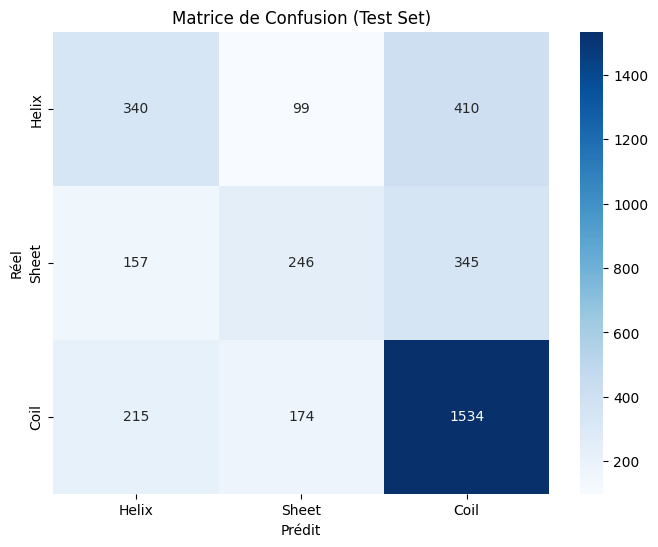

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sn
import matplotlib.pyplot as plt

# 1. Prédiction sur le Test
model.eval()
with torch.no_grad():
    # Attention: Assure-toi que x_one_hot_test est sur le bon device
    logits = model(x_one_hot_test.to(device))
    y_pred = torch.argmax(logits, dim=1).cpu()
    y_true = y_test.cpu()

# 2. Rapport détaillé
print(classification_report(y_true, y_pred, target_names=['Helix (h)', 'Sheet (e)', 'Coil (_)']))

# 3. Matrice de Confusion
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sn.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
           xticklabels=['Helix', 'Sheet', 'Coil'], 
           yticklabels=['Helix', 'Sheet', 'Coil'])
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.title('Matrice de Confusion (Test Set)')
plt.show()

In [ ]:
"""model = MLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)
loss_fn = nn.CrossEntropyLoss()
epochs = 900

train_loss_history = []
val_acc_history = []

for i in range(epochs):
    model.train()
    
    # 1. On initialise les compteurs à 0 au début de l'époque
    train_loss = 0 
    train_correct = 0
    train_total = 0
    
    for x_one_hot_train_batch, y_true_batch in train_loader:
        # Transfert GPU (si tes loaders ne le sont pas déjà)
        x_one_hot_train_batch = x_one_hot_train_batch.to(device)
        y_true_batch = y_true_batch.to(device)

        # Forward
        y_train = model(x_one_hot_train_batch)
        loss = loss_fn(y_train, y_true_batch)
        
        # Backward
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # 2. On cumule la Loss
        train_loss += loss.item()
        
        # 3. On cumule les Bonnes Réponses pour l'Accuracy Globale
        y_pred = torch.argmax(y_train, dim=1)
        train_correct += (y_pred == y_true_batch).sum().item()
        train_total += y_true_batch.size(0)
        
    # Calcul des moyennes sur TOUTE l'époque
    train_avg_loss = train_loss / len(train_loader)
    train_avg_acc = train_correct / train_total  # C'est ça que tu voulais !
    
    train_loss_history.append(train_avg_loss)
    
    # Affichage tous les 100 tours
    if i % 100 == 0:
        
        # Validation
        model.eval()
        val_correct = 0
        val_total = 0
        
        with torch.no_grad():
            for x_one_hot_val_batch, y_val_batch in val_loader:
                x_one_hot_val_batch = x_one_hot_val_batch.to(device)
                y_val_batch = y_val_batch.to(device)

                y_val_train = model(x_one_hot_val_batch)
                y_val_pred = torch.argmax(y_val_train, dim=1)
                
                val_correct += (y_val_pred == y_val_batch).sum().item()
                val_total += y_val_batch.size(0)
        
        val_acc = val_correct / val_total
        val_acc_history.append(val_acc)
        
        print(f"Epoch {i:3d} | Loss: {train_avg_loss:.4f} | Train Acc Global: {train_avg_acc*100:.2f}% | Val Acc Global: {val_acc*100:.2f}%")"""

'model = MLP().to(device)\noptimizer = torch.optim.Adam(model.parameters(), lr=0.0001)\nloss_fn = nn.CrossEntropyLoss()\nepochs = 900\n\ntrain_loss_history = []\nval_acc_history = []\n\nfor i in range(epochs):\n    model.train()\n    \n    # 1. On initialise les compteurs à 0 au début de l\'époque\n    train_loss = 0 \n    train_correct = 0\n    train_total = 0\n    \n    for x_one_hot_train_batch, y_true_batch in train_loader:\n        # Transfert GPU (si tes loaders ne le sont pas déjà)\n        x_one_hot_train_batch = x_one_hot_train_batch.to(device)\n        y_true_batch = y_true_batch.to(device)\n\n        # Forward\n        y_train = model(x_one_hot_train_batch)\n        loss = loss_fn(y_train, y_true_batch)\n        \n        # Backward\n        optimizer.zero_grad()\n        loss.backward()\n        optimizer.step()\n        \n        # 2. On cumule la Loss\n        train_loss += loss.item()\n        \n        # 3. On cumule les Bonnes Réponses pour l\'Accuracy Globale\n       

In [ ]:
"""model=MLP().to(device)
optimizer=torch.optim.Adam(model.parameters(),lr=0.0001)
loss_fn=nn.CrossEntropyLoss()
#epoch=700 ou 900 bon resultat
epochs=900
for i in range(epochs):
        model.train()
        y_train = model(x_one_hot_train)
        loss=loss_fn(y_train,y_true)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if i%100==0:
            y_pred=torch.argmax(y_train,dim=1)
            accuracy=(y_pred==y_true).float().mean()
            print(f"Loss : {loss.item()}  Accuracy : {accuracy.item()*100:.2f}%")

            with torch.no_grad():

                model.eval()
                y_val_train=model(x_one_hot_val)
                y_val_pred=torch.argmax(y_val_train,dim=1)
                accuracy=(y_val_pred==y_val).float().mean()
                print(f"Accuracy_val : {accuracy*100:.2f}%")
                
"""


'model=MLP().to(device)\noptimizer=torch.optim.Adam(model.parameters(),lr=0.0001)\nloss_fn=nn.CrossEntropyLoss()\n#epoch=700 ou 900 bon resultat\nepochs=900\nfor i in range(epochs):\n        model.train()\n        y_train = model(x_one_hot_train)\n        loss=loss_fn(y_train,y_true)\n        optimizer.zero_grad()\n        loss.backward()\n        optimizer.step()\n        if i%100==0:\n            y_pred=torch.argmax(y_train,dim=1)\n            accuracy=(y_pred==y_true).float().mean()\n            print(f"Loss : {loss.item()}  Accuracy : {accuracy.item()*100:.2f}%")\n\n            with torch.no_grad():\n\n                model.eval()\n                y_val_train=model(x_one_hot_val)\n                y_val_pred=torch.argmax(y_val_train,dim=1)\n                accuracy=(y_val_pred==y_val).float().mean()\n                print(f"Accuracy_val : {accuracy*100:.2f}%")\n                \n'

In [ ]:

model.eval()

with torch.no_grad():
    y_test_train=model(x_one_hot_test)
    y_test_pred=torch.argmax(y_test_train,dim=1)
    accuracy=(y_test_pred==y_test).float().mean()
    print(f"Accuracy : {accuracy*100:.2f}%")


Accuracy : 60.23%


In [ ]:
#torch.save(model.state_dict(),'model_v4.pth')

In [ ]:
#model.load_state_dict(torch.load('model_v3.pth',map_location=torch.device('cpu')))

In [ ]:

model.eval()

with torch.no_grad():
    y_test_train=model(x_one_hot_test)
    y_test_pred=torch.argmax(y_test_train,dim=1)
    accuracy=(y_test_pred==y_test).float().mean()
    print(f"Accuracy : {accuracy*100:.2f}%")


Accuracy : 60.23%


### Score

- Score de 63.69 pour model v3